<a href="https://colab.research.google.com/github/juanchos37/control-microbiologico-python/blob/main/Topo_App.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# paso 1: instalar y cargar libreria basicas
import pandas as pd
import numpy as np

# PASO 2: Simular datos capturados en campo (Punto, Norte, Este, Cota, Descripción)
# Imagina que estos son los datos que tomaste hoy trabajando en Santa Marta
datos_campos = {
    'punto':[1, 2, 3, 4, 5],
    'norte':[850100.25, 850105.10, np.nan, 850115.80, 850120.35],# El punto 3 falló
    'este':[1020300.45, 1020302.15, 1020305.60, 1020310.00, 1020312.90],
    'cota_z': [15.2, 15.4, 15.8, 16.1, 15.9],
    'codigo':['Eje_Via', 'Eje_Via', 'Borde_Via', 'Borde_Via', 'ERROR_DIGITACION']

    }

# PASO 3: Crear el DataFrame (Nuestra tabla de trabajo)

df = pd.DataFrame(datos_campos)
print('---DATOS ORIGINALES DEL CAMPO---')
print(df)

# PASO 4: Limpieza de datos (Data Cleaning)
# 1. Eliminar filas que no tengan la coordenada Norte (falla de equipo)

df_limpio = df.dropna(subset=['norte'])

# 2. Reemplazar códigos erróneos usando condiciones lógicas
df_limpio['codigo'] = df_limpio['codigo'].replace('ERROR_DIGITACION', 'Borde_Via')

print('\n---DATOS LIMPIOS DEL CAMPO---')

print(df_limpio)



---DATOS ORIGINALES DEL CAMPO---
   punto      norte        este  cota_z            codigo
0      1  850100.25  1020300.45    15.2           Eje_Via
1      2  850105.10  1020302.15    15.4           Eje_Via
2      3        NaN  1020305.60    15.8         Borde_Via
3      4  850115.80  1020310.00    16.1         Borde_Via
4      5  850120.35  1020312.90    15.9  ERROR_DIGITACION

---DATOS LIMPIOS DEL CAMPO---
   punto      norte        este  cota_z     codigo
0      1  850100.25  1020300.45    15.2    Eje_Via
1      2  850105.10  1020302.15    15.4    Eje_Via
3      4  850115.80  1020310.00    16.1  Borde_Via
4      5  850120.35  1020312.90    15.9  Borde_Via


/tmp/ipykernel_1037/1428302612.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_limpio['codigo'] = df_limpio['codigo'].replace('ERROR_DIGITACION', 'Borde_Via')


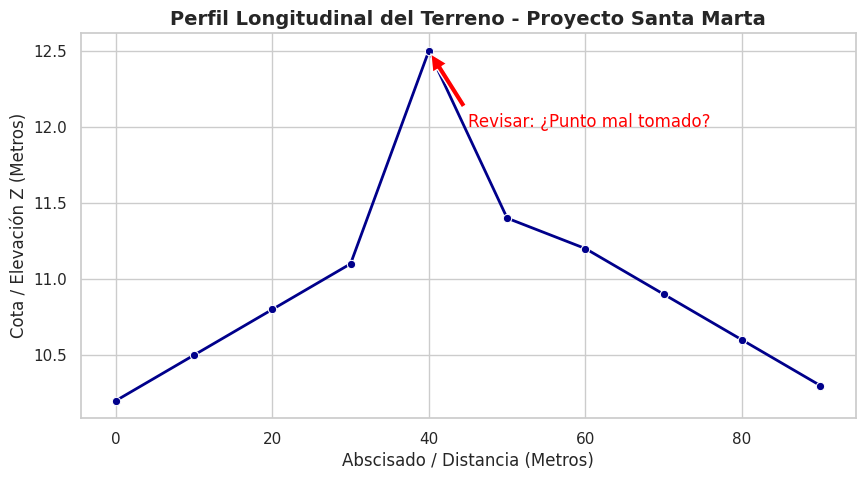

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Simulamos la medición de un perfil longitudinal de una vía (Distancia vs Altura)
distancia = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]
altura_z =  [10.2, 10.5, 10.8, 11.1, 12.5, 11.4, 11.2, 10.9, 10.6, 10.3] # El 12.5 parece un error humano

df_perfil = pd.DataFrame({'Distancia': distancia, 'Altura': altura_z})

# Configurar el estilo visual con Seaborn
sns.set_theme(style="whitegrid")

# Crear el gráfico
plt.figure(figsize=(10, 5))
sns.lineplot(data=df_perfil, x='Distancia', y='Altura', marker='o', color='darkblue', linewidth=2)

# Añadir títulos técnicos
plt.title('Perfil Longitudinal del Terreno - Proyecto Santa Marta', fontsize=14, fontweight='bold')
plt.xlabel('Abscisado / Distancia (Metros)', fontsize=12)
plt.ylabel('Cota / Elevación Z (Metros)', fontsize=12)

# Resaltar el posible error de medición en la obra con una anotación
plt.annotate('Revisar: ¿Punto mal tomado?', xy=(40, 12.5), xytext=(45, 12.0),
             arrowprops=dict(facecolor='red', shrink=0.05), color='red')

plt.show()


--- GEODATAFRAME (Fíjate en la columna 'geometry') ---
                 geometry
0  POINT (1020300 850100)
1  POINT (1020350 850100)
2  POINT (1020350 850150)
3  POINT (1020300 850150)


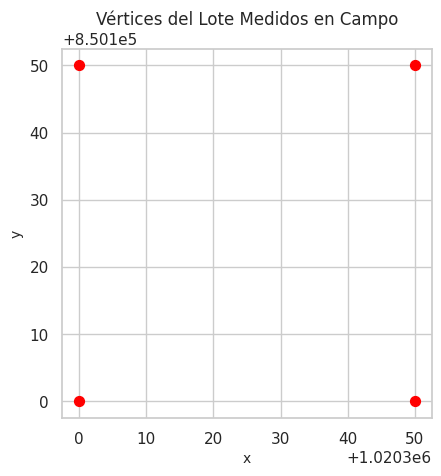

In [6]:
# PASO 1: Instalar GeoPandas en el entorno de Colab (Obligatorio cada vez que abras el cuaderno)
!pip install geopandas shapely

import geopandas as gpd
from shapely.geometry import Point

# PASO 2: Definir las coordenadas del lindero de un lote en Santa Marta (Este, Norte)
coordenadas_esquinas = [
    Point(1020300, 850100),
    Point(1020350, 850100),
    Point(1020350, 850150),
    Point(1020300, 850150)
]

# PASO 3: Convertir puntos en un GeoDataFrame
# Usamos un sistema de coordenadas de referencia ficticio o local
gdf_puntos = gpd.GeoDataFrame(geometry=coordenadas_esquinas)

print("--- GEODATAFRAME (Fíjate en la columna 'geometry') ---")
print(gdf_puntos)

# PASO 4: Graficar los vértices espacialmente
gdf_puntos.plot(color='red', markersize=50)
plt.title('Vértices del Lote Medidos en Campo')
plt.grid(True)
plt.show()


In [7]:
# PASO 1: Instalar el servidor de PostgreSQL y la librería para conectar desde Python (psycopg2)
!apt-get -y -qq update
!apt-get -y -qq install postgresql postgresql-contrib
!pip install psycopg2-binary

# PASO 2: Iniciar el servicio del servidor de PostgreSQL virtualizado
!service postgresql start

# PASO 3: Configurar un usuario y una base de datos para tu proyecto de topografía
# Crearemos la base de datos llamada 'santa_marta_obras'
!sudo -u postgres psql -c "CREATE USER cadenerotech WITH PASSWORD 'sena2027';"
!sudo -u postgres psql -c "CREATE DATABASE santa_marta_obras OWNER cadenerotech;"

# 🔌 PASO 4: Establecer la conexión desde Python usando 'psycopg2'
import psycopg2

conexion = psycopg2.connect(
    host="localhost",
    database="santa_marta_obras",
    user="cadenerotech",
    password="sena2027"
)

# El 'cursor' es el encargado de ejecutar los comandos SQL
cursor = conexion.cursor()
print("¡CONEXIÓN EXITOSA! Te has conectado a PostgreSQL correctamente.")

# 🛠️ PASO 5: Crear una tabla para guardar los puntos topográficos del frente de obra
cursor.execute("""
CREATE TABLE IF NOT EXISTS control_topografico (
    id_punto SERIAL PRIMARY KEY,
    nombre_estacion VARCHAR(50),
    coordenada_norte NUMERIC(12, 3),
    coordenada_este NUMERIC(12, 3),
    elevacion_z NUMERIC(6, 2),
    fecha_medicion DATE DEFAULT CURRENT_DATE
);
""")
conexion.commit() # Guardar los cambios en la base de datos
print("Tabla 'control_topografico' creada con éxito.")

# 📝 PASO 6: Insertar datos reales que recolectaste en el terreno
puntos_leidos = [
    ('ST-01', 850100.250, 1020300.450, 15.20),
    ('ST-02', 850120.110, 1020315.300, 15.45),
    ('ST-03', 850145.890, 1020330.120, 15.80)
]

for punto in puntos_leidos:
    cursor.execute("""
    INSERT INTO control_topografico (nombre_estacion, coordenada_norte, coordenada_este, elevacion_z)
    VALUES (%s, %s, %s, %s);
    """, punto)

conexion.commit()
print("¡Puntos de campo insertados en la base de datos!")

# 🔍 PASO 7: Hacer una consulta SQL (SELECT) para verificar la información
cursor.execute("SELECT * FROM control_topografico WHERE elevacion_z > 15.30;")
resultados = cursor.fetchall()

print("\n--- PUNTOS CON ELEVACIÓN MAYOR A 15.30 METROS ---")
for fila in resultados:
    print(f"ID: {fila[0]} | Estación: {fila[1]} | N: {fila[2]} | E: {fila[3]} | Z: {fila[4]} mts")

# 🔒 PASO 8: Cerrar las conexiones de seguridad
cursor.close()
conexion.close()
print("\nConexión cerrada de forma segura.")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Preconfiguring packages ...
Selecting previously unselected package libjson-perl.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../00-libjson-perl_4.10000-1_all.deb ...
Unpacking libjson-perl (4.10000-1) ...
Selecting previously unselected package postgresql-client-common.
Preparing to unpack .../01-postgresql-client-common_257build1.1_all.deb ...
Unpacking postgresql-client-common (257build1.1) ...
Selecting previously unselected package ssl-cert.
Preparing to unpack .../02-ssl-cert_1.1.2ubuntu1_all.deb ...
Unpacking ssl-cert (1.1.2ubuntu1) ...
Selecting previously unselected package postgresql-common.
Preparing to unpack .../03-postgresql-common_257build1.1_all.deb ...
Adding 'diversion of /usr/bin/pg_config to /usr/bin/pg_config.libpq-dev by postgres

In [8]:
# PASO 1: Volver a abrir la conexión (ya que la cerramos en el paso anterior)
import psycopg2
import pandas as pd

conexion = psycopg2.connect(
    host="localhost",
    database="santa_marta_obras",
    user="cadenerotech",
    password="sena2027"
)

# PASO 2: Escribir la consulta SQL que queremos hacer
# Traeremos todos los puntos de la tabla
consulta_sql = "SELECT * FROM control_topografico;"

# 🚀 PASO 3: La magia de Pandas. Lee la base de datos y la convierte en tabla automáticamente
df_topografia = pd.read_sql_query(consulta_sql, conexion)

# PASO 4: Cerrar la conexión por seguridad
conexion.close()

# PASO 5: Ver y trabajar con nuestros datos en Pandas
print("--- DATOS EXTRAÍDOS DE POSTGRESQL DIRECTO A PANDAS ---")
print(df_topografia)

# Ahora puedes usar todo el poder de Pandas que ya conoces:
# Por ejemplo, calcular el promedio de las cotas (alturas) de la obra
cota_promedio = df_topografia['elevacion_z'].mean()
print(f"\nLa altura promedio del terreno medido es: {cota_promedio:.2f} metros.")


--- DATOS EXTRAÍDOS DE POSTGRESQL DIRECTO A PANDAS ---
   id_punto nombre_estacion  coordenada_norte  coordenada_este  elevacion_z  \
0         1           ST-01         850100.25       1020300.45        15.20   
1         2           ST-02         850120.11       1020315.30        15.45   
2         3           ST-03         850145.89       1020330.12        15.80   

  fecha_medicion  
0     2026-11-03  
1     2026-11-03  
2     2026-11-03  

La altura promedio del terreno medido es: 15.48 metros.


/tmp/ipykernel_1037/2160012573.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_topografia = pd.read_sql_query(consulta_sql, conexion)


In [11]:
# PASO 1: Instalar la extensión PostGIS en el sistema operativo de Colab
!apt-get -y -qq install postgresql-16-postgis-3
!service postgresql restart
!sudo -u postgres psql -d santa_marta_obras -c "CREATE EXTENSION IF NOT EXISTS postgis;"

# PASO 2: Volver a conectar a nuestra base de datos con psycopg2
import psycopg2
import pandas as pd

conexion = psycopg2.connect(
    host="localhost",
    database="santa_marta_obras",
    user="cadenerotech",
    password="sena2027"
)
cursor = conexion.cursor()



# 🛠️ PASO 4: Crear una nueva tabla que use geometría real (Puntos espaciales)
# Usaremos el SRID 3116 (Magna-Sirgas / Colombia Bogotá, ideal para topografía local)
cursor.execute("""
CREATE TABLE IF NOT EXISTS estaciones_georeferenciadas (
    id SERIAL PRIMARY KEY,
    nombre VARCHAR(10),
    geometria GEOMETRY(Point, 3116)
);
""")
conexion.commit()

# 📝 PASO 5: Insertar puntos usando la función ST_GeomFromText de PostGIS
# Imagina que son dos estacas que clavaste como cadenero en la playa de Santa Marta
# Formato: ST_GeomFromText('POINT(Este Norte)', SRID)
cursor.execute("""
INSERT INTO estaciones_georeferenciadas (nombre, geometria) VALUES
('Hito_A', ST_GeomFromText('POINT(1020300.000 850100.000)', 3116)),
('Hito_B', ST_GeomFromText('POINT(1020340.000 850130.000)', 3116));
""")
conexion.commit()
print("Puntos geométricos insertados.")

# 📐 PASO 6: La magia de PostGIS. Calcular la distancia matemática en metros usando SQL
# Usamos la función ST_Distance entre la geometría del Hito_A y el Hito_B
consulta_distancia = """
SELECT ST_Distance(
    (SELECT geometria FROM estaciones_georeferenciadas WHERE nombre = 'Hito_A'),
    (SELECT geometry FROM (SELECT geometria FROM estaciones_georeferenciadas WHERE nombre = 'Hito_B') as sub)
) AS distancia_metros;
"""

# Nota: Optimizamos la consulta para que PostGIS calcule directo en el servidor
cursor.execute("""
SELECT ST_Distance(a.geometria, b.geometria) as distancia
FROM estaciones_georeferenciadas a, estaciones_georeferenciadas b
WHERE a.nombre = 'Hito_A' AND b.nombre = 'Hito_B';
""")
distancia_calculada = cursor.fetchone()[0]

print(f"\n📏 CÁLCULO DE CAMPO:")
print(f"La distancia real medida por PostGIS entre el Hito_A y el Hito_B es de: {distancia_calculada:.3f} metros.")

# Cerrar procesos
cursor.close()
conexion.close()


[ OK ]
CREATE EXTENSION
Puntos geométricos insertados.

📏 CÁLCULO DE CAMPO:
La distancia real medida por PostGIS entre el Hito_A y el Hito_B es de: 50.000 metros.


In [17]:
# PASO 1: Instalar Folium y herramientas de conversión de coordenadas
!pip install folium geopandas shapely pyproj

import geopandas as gpd
import folium
from shapely.geometry import Point

print("Librerías listas para mapear.")

# 🗺️ PASO 2: Simular los puntos que mediste hoy en campo (Coordenadas Oficiales de Colombia)
# Corregido: Agregamos los datos numéricos que hacían falta
datos_topografo = {
    'Estacion': ['Punto_Inicio_Obra', 'Hito_Intermedio', 'Punto_Final_Obra'],
    'Este_X': [4845100.0, 4845150.0, 4845220.0],
    'Norte_Y': [2785100.0, 2785130.0, 2785180.0],
    'Detalle': ['Estaca Base 01', 'Punto de Control', 'Límite de Propiedad']
}


# Crear el GeoDataFrame especificando el sistema de coordenadas de origen (EPSG:9377 - Origen Único Nacional Colombia)
geometrias = [Point(x, y) for x, y in zip(datos_topografo['Este_X'], datos_topografo['Norte_Y'])]
gdf_colombia = gpd.GeoDataFrame(datos_topografo, geometry=geometrias, crs="EPSG:9377")

# 🔄 PASO 3: Conversión mágica de coordenadas planas a geográficas (WGS84 - EPSG:4326)
# Este paso es vital para que internet entienda dónde ubicar los puntos
gdf_gps = gdf_colombia.to_crs("EPSG:4326")

# Extraer la latitud y longitud calculadas por Python
gdf_gps['Latitud'] = gdf_gps.geometry.y
gdf_gps['Longitud'] = gdf_gps.geometry.x

# 📍 PASO 4 (SOLUCIÓN DEFINITIVA): Crear el lienzo con mapa satelital libre de bloqueos
lat_centro = gdf_gps['Latitud'].mean()
lon_centro = gdf_gps['Longitud'].mean()

# Usamos la capa Satelital de Esri, que permite conexiones directas desde Colab sin restricciones de llave
mapa_santa_marta = folium.Map(
    location=[lat_centro, lon_centro],
    zoom_start=16,
    tiles="https://arcgisonline.com{z}/{y}/{x}",
    attr="Tiles © Esri — Source: Esri, i-cubed, USDA, USGS, AEX, GeoEye, Getmapping, Aerogrid, IGN, IGP, UPR-EGP, and the GIS User Community"
)

# Creamos el mapa usando azulejos libres de CartoDB (Fondo claro y elegante)
mapa_santa_marta = folium.Map(
    location=[lat_centro, lon_centro],
    zoom_start=16,
    tiles="https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
    attr="Tiles: © CARTO / Map data: © OpenStreetMap contributors"
)


# Crear mapa base interactivo
mapa_santa_marta = folium.Map(location=[lat_centro, lon_centro], zoom_start=16, tiles="OpenStreetMap")

# 📌 PASO 5: Dibujar los puntos y líneas de la topografía en el mapa
puntos_linea = []

for indice, fila in gdf_gps.iterrows():
    coordenadas_punto = [fila['Latitud'], fila['Longitud']]
    puntos_linea.append(coordenadas_punto) # Guardar para dibujar la línea después

    # Crear un marcador con un globo de información interactivo (Popup)
    contenido_globo = f"<b>Estación:</b> {fila['Estacion']}<br><b>Nota:</b> {fila['Detalle']}"

    folium.Marker(
        location=coordenadas_punto,
        popup=folium.Popup(contenido_globo, max_width=300),
        tooltip=fila['Estacion'],
        icon=folium.Icon(color='blue', icon='info-sign')
    ).add_to(mapa_santa_marta)

# Dibujar una línea roja que una los puntos simulando el eje de la vía medida
folium.PolyLine(locations=puntos_linea, color="red", weight=3, opacity=0.8).add_to(mapa_santa_marta)

# 🖥️ PASO 6: Mostrar el mapa en la pantalla de Google Colab
print("\n--- ¡MAPA GENERADO CON ÉXITO! Haz clic en los globos azules ---")
mapa_santa_marta


Librerías listas para mapear.

--- ¡MAPA GENERADO CON ÉXITO! Haz clic en los globos azules ---


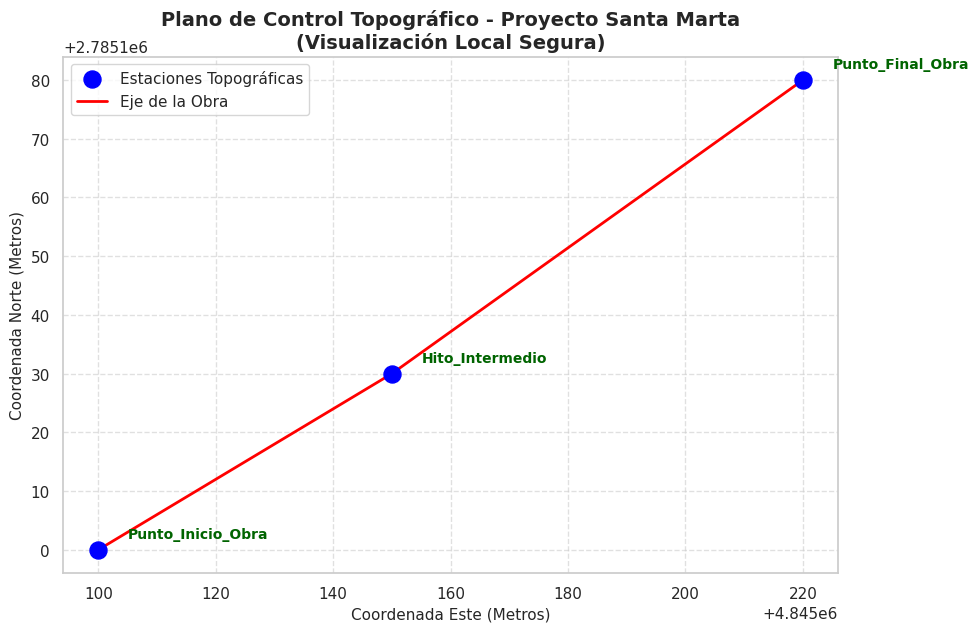

In [18]:
# PASO 1: Instalar y cargar librerías base (Seguras y locales)
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# 🗺️ PASO 2: Cargar las coordenadas del lote medido en Santa Marta
datos_topografo = {
    'Estacion': ['Punto_Inicio_Obra', 'Hito_Intermedio', 'Punto_Final_Obra'],
    'Este_X': [4845100.0, 4845150.0, 4845220.0],
    'Norte_Y': [2785100.0, 2785130.0, 2785180.0],
    'Detalle': ['Estaca Base 01', 'Punto de Control', 'Límite de Propiedad']
}

# Crear el GeoDataFrame en el sistema de coordenadas oficial de Colombia
geometrias = [Point(x, y) for x, y in zip(datos_topografo['Este_X'], datos_topografo['Norte_Y'])]
gdf_obra = gpd.GeoDataFrame(datos_topografo, geometry=geometrias, crs="EPSG:9377")

# 📊 PASO 3: Graficar directamente en la pantalla de Colab usando Matplotlib
fig, ax = plt.subplots(figsize=(10, 8))

# 1. Dibujar las estaciones como puntos azules grandes
gdf_obra.plot(ax=ax, color='blue', markersize=150, zorder=5, label='Estaciones Topográficas')

# 2. Dibujar las líneas que unen los puntos (el polígono o eje de la vía)
coordenadas_linea_x = datos_topografo['Este_X']
coordenadas_linea_y = datos_topografo['Norte_Y']
ax.plot(coordenadas_linea_x, coordenadas_linea_y, color='red', linestyle='-', linewidth=2, label='Eje de la Obra')

# 3. Colocar los nombres de las estaciones al lado de cada punto en el mapa
for indice, fila in gdf_obra.iterrows():
    ax.text(fila.geometry.x + 5, fila.geometry.y + 2, fila['Estacion'],
            fontsize=10, fontweight='bold', color='darkgreen')

# 🛠️ PASO 4: Configurar los detalles técnicos del plano gráfico
ax.set_title('Plano de Control Topográfico - Proyecto Santa Marta\n(Visualización Local Segura)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Coordenada Este (Metros)', fontsize=11)
ax.set_ylabel('Coordenada Norte (Metros)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6) # Cuadrícula topográfica de fondo
ax.legend(loc='upper left')

# Mostrar el gráfico en Colab
plt.show()
